# 4 One-Dimensional Discrete Wavelet Transform

## 4.3 Process of Single-level 

### 4.3.4 PyWavelets Implementations

**1. Single-level Decomposition**

**Example: Single-Level Decomposition**

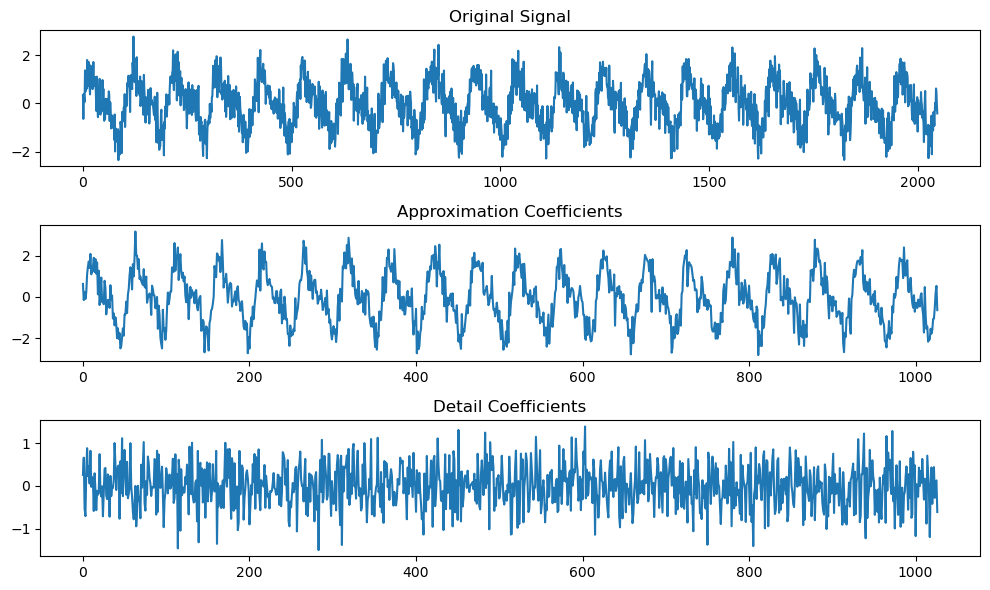

In [ ]:
import pywt
import numpy as np
import matplotlib.pyplot as plt

# Simulated noisy signal
t = np.linspace(0, 1, num=2048)
signal = np.sin(40 * np.pi * t) + 0.5 * np.sin(80 * np.pi * t)
signal += 0.5 * np.random.randn(*t.shape)  # add noise


# Single-level decomposition
cA, cD = pywt.dwt(signal, 'db4')

# Plot
plt.figure(figsize=(10, 6))
plt.subplot(3, 1, 1)
plt.plot(signal)
plt.title('Original Signal')
plt.subplot(3, 1, 2)
plt.plot(cA)
plt.title('Approximation Coefficients')
plt.subplot(3, 1, 3)
plt.plot(cD)
plt.title('Detail Coefficients')
plt.tight_layout()
plt.savefig('./output/4.4_1l_wavelet_decomposition.png')
plt.show()

**(b) Using `downcoef` for Partial Decomposition**

**Example: Single-Level Partial Decomposition**


In [29]:
import pywt
import numpy as np

# Simulated noisy signal
t = np.linspace(0, 1, num=2048)
signal = np.sin(40 * np.pi * t) + 0.5 * np.sin(80 * np.pi * t)
signal += 0.5 * np.random.randn(*t.shape)  # add noise

# Compute only approximation coefficients at level 1
cA1 = pywt.downcoef('a', signal, 'db4')

# Compute only detail coefficients at level 1
cD1 = pywt.downcoef('d', signal, 'db4')

print(f"Approximation coefficients (level 1): {cA1.shape}")
print(f"Detail coefficients (level 1): {cD1.shape}")

# Compare with full DWT
cA, cD = pywt.dwt(signal, 'db4')

# Numerical error metrics
approx_error_mean = np.mean(np.abs(cA1 - cA))
approx_error_max = np.max(np.abs(cA1 - cA))

detail_error_mean = np.mean(np.abs(cD1 - cD))
detail_error_max = np.max(np.abs(cD1 - cD))

print("\nError metrics between downcoef() and full DWT:")
print(f"Approximation -> Mean error: {approx_error_mean:.2e}, Max error: {approx_error_max:.2e}")
print(f"Detail       -> Mean error: {detail_error_mean:.2e}, Max error: {detail_error_max:.2e}")

# Boolean closeness check
if np.allclose(cA1, cA) and np.allclose(cD1, cD):
    print("\nThe coefficients match those from full DWT (within numerical tolerance).")
else:
    print("\nThe coefficients differ.")



Approximation coefficients (level 1): (1027,)
Detail coefficients (level 1): (1027,)

Error metrics between downcoef() and full DWT:
Approximation -> Mean error: 0.00e+00, Max error: 0.00e+00
Detail       -> Mean error: 0.00e+00, Max error: 0.00e+00

The coefficients match those from full DWT (within numerical tolerance).


**2. Single-level Reconstruction**

**(b) Example 2: Single-Level Reconstruction**

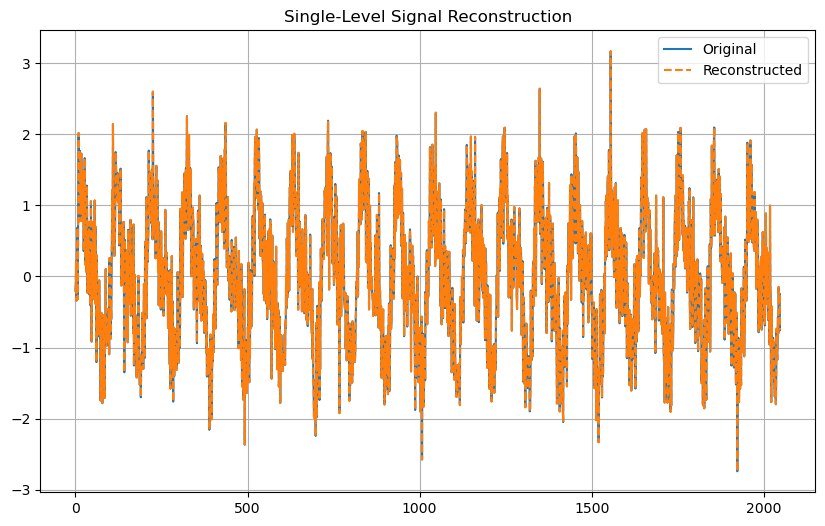

In [ ]:
# Step 1: Repeat the decompose part in example 1
import pywt
import numpy as np
import matplotlib.pyplot as plt

# Simulated noisy signal
t = np.linspace(0, 1, num=2048)
signal = np.sin(40 * np.pi * t) + 0.5 * np.sin(80 * np.pi * t)
signal += 0.5 * np.random.randn(*t.shape)  # add noise

# Single-level decomposition
cA, cD = pywt.dwt(signal, 'db4')

# Step 2: Reconstruct
signal_rec = pywt.idwt(cA, cD, 'db4')

# Step 3: Visualize the result
plt.plot(signal, label='Original')
plt.plot(signal_rec, '--', label='Reconstructed')
plt.title("Single-Level Signal Reconstruction")
plt.legend()
plt.grid(True)
plt.savefig('./output/4.5_1l_wavelet_reconstruction.png')
plt.show()

In [11]:
# Compute reconstruction errors
mean_error = np.mean(np.abs(signal - signal_rec))
max_error = np.max(np.abs(signal - signal_rec))
print(f"Reconstruction Mean Error: {mean_error:.2e}")
print(f"Reconstruction Max Error: {max_error:.2e}")

Reconstruction Mean Error: 8.93e-17
Reconstruction Max Error: 8.88e-16


**3. Single-level Partial Reconstruction**

**(c) Example: Comparing `upcoef()` vs `idwt()` for Partial Reconstruction with Error Metrics**

Numerical error metrics between upcoef() and idwt():
Approximation -> Mean error: 0.00e+00, Max error: 0.00e+00
Detail       -> Mean error: 0.00e+00, Max error: 0.00e+00


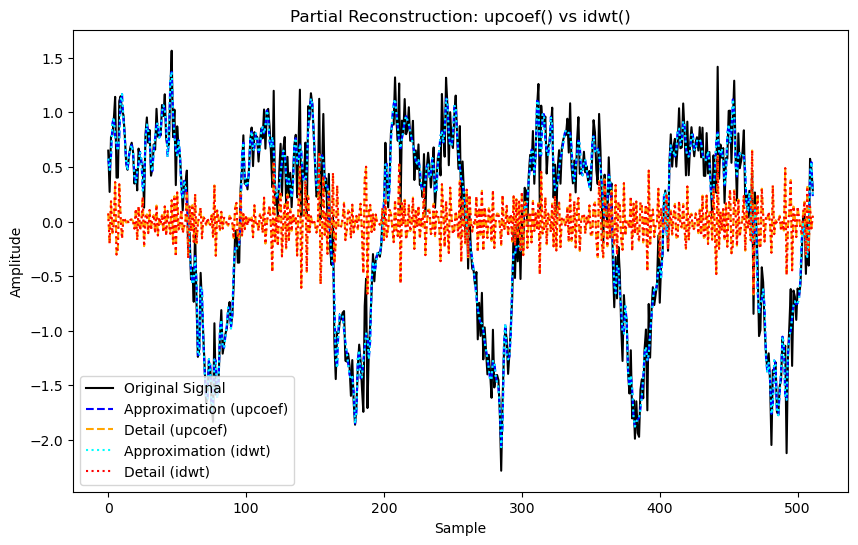

In [ ]:
import pywt
import numpy as np
import matplotlib.pyplot as plt

# Generate a simple signal
x = np.linspace(0, 1, 512)
signal = np.sin(10 * np.pi * x) + 0.5 * np.cos(20 * np.pi * x)
signal += 0.3 * np.random.randn(*x.shape)  # add noise
n = len(signal)

# Perform single-level DWT
wavelet = 'db4'
cA, cD = pywt.dwt(signal, wavelet)

# Partial reconstruction using upcoef() with 'take' to match original length
approx_up = pywt.upcoef('a', cA, wavelet, level=1, take=n)
detail_up = pywt.upcoef('d', cD, wavelet, level=1, take=n)

# Partial reconstruction using idwt()
approx_idwt = pywt.idwt(cA, None, wavelet)
detail_idwt = pywt.idwt(None, cD, wavelet)

# Compute numerical error metrics
approx_error_mean = np.mean(np.abs(approx_up - approx_idwt))
approx_error_max = np.max(np.abs(approx_up - approx_idwt))

detail_error_mean = np.mean(np.abs(detail_up - detail_idwt))
detail_error_max = np.max(np.abs(detail_up - detail_idwt))

print("Numerical error metrics between upcoef() and idwt():")
print(f"Approximation -> Mean error: {approx_error_mean:.2e}, Max error: {approx_error_max:.2e}")
print(f"Detail       -> Mean error: {detail_error_mean:.2e}, Max error: {detail_error_max:.2e}")

# Plot results
plt.figure(figsize=(10,6))
plt.plot(signal, label='Original Signal', color='black')
plt.plot(approx_up, '--', label='Approximation (upcoef)', color='blue')
plt.plot(detail_up, '--', label='Detail (upcoef)', color='orange')
plt.plot(approx_idwt, ':', label='Approximation (idwt)', color='cyan')
plt.plot(detail_idwt, ':', label='Detail (idwt)', color='red')
plt.legend()
plt.title('Partial Reconstruction: upcoef() vs idwt()')
plt.xlabel('Sample')
plt.ylabel('Amplitude')
plt.savefig('./output/4.6_1l_partial_reconstruction_comparison.png')
plt.show()



## 4.4 Process of Multi-level DWT


### 4.4.4 Implementations in PyWavelets

**1. Multi-level Decomposition**

**(b) Example 5: Multi-Level Decomposition**

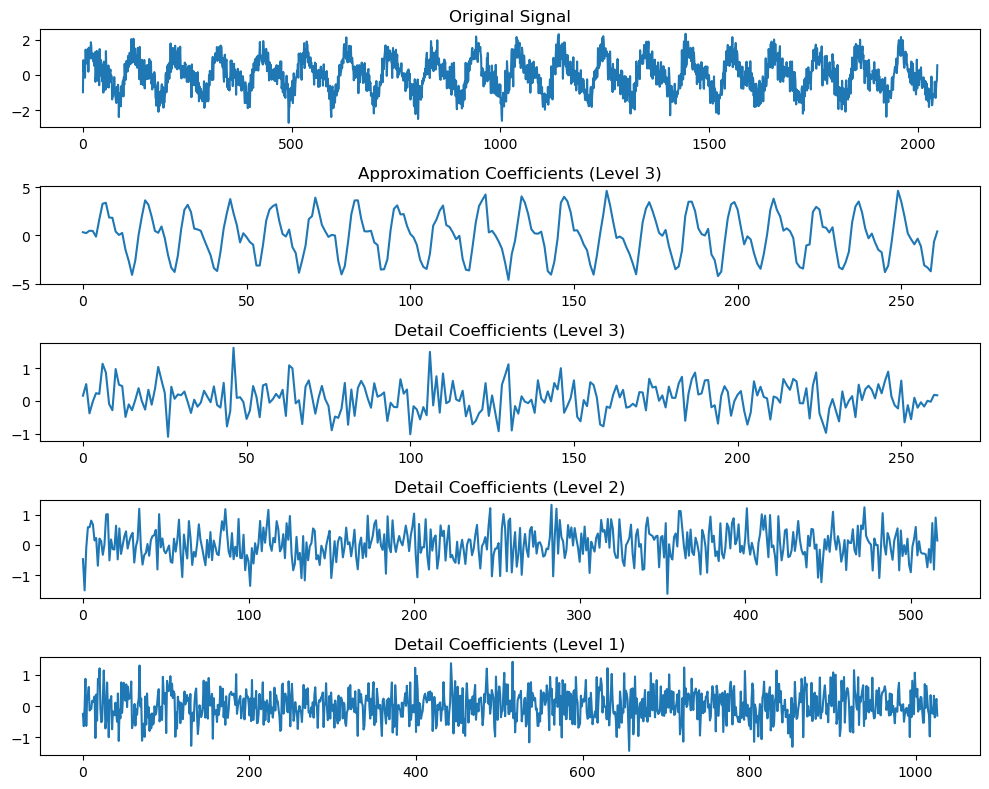

In [ ]:
import pywt
import numpy as np
import matplotlib.pyplot as plt

# Simulated noisy signal
t = np.linspace(0, 1, num=2048)
signal = np.sin(40 * np.pi * t) + 0.5 * np.sin(80 * np.pi * t)
signal += 0.5 * np.random.randn(*t.shape)  # add noise

# Perform 3-level decomposition
wavelet = 'db4'
coeffs = pywt.wavedec(signal, wavelet, level=3)

# Extract coefficients
cA3, cD3, cD2, cD1 = coeffs

# Plot coefficients
plt.figure(figsize=(10, 8))

plt.subplot(5, 1, 1)
plt.plot(signal)
plt.title("Original Signal")

plt.subplot(5, 1, 2)
plt.plot(cA3)
plt.title("Approximation Coefficients (Level 3)")

plt.subplot(5, 1, 3)
plt.plot(cD3)
plt.title("Detail Coefficients (Level 3)")

plt.subplot(5, 1, 4)
plt.plot(cD2)
plt.title("Detail Coefficients (Level 2)")

plt.subplot(5, 1, 5)
plt.plot(cD1)
plt.title("Detail Coefficients (Level 1)")

plt.tight_layout()
plt.savefig("./output/4.10_multi-level_decomposition.png")
plt.show()

**(d) Example 6: Multi-level Partial Decomposition**

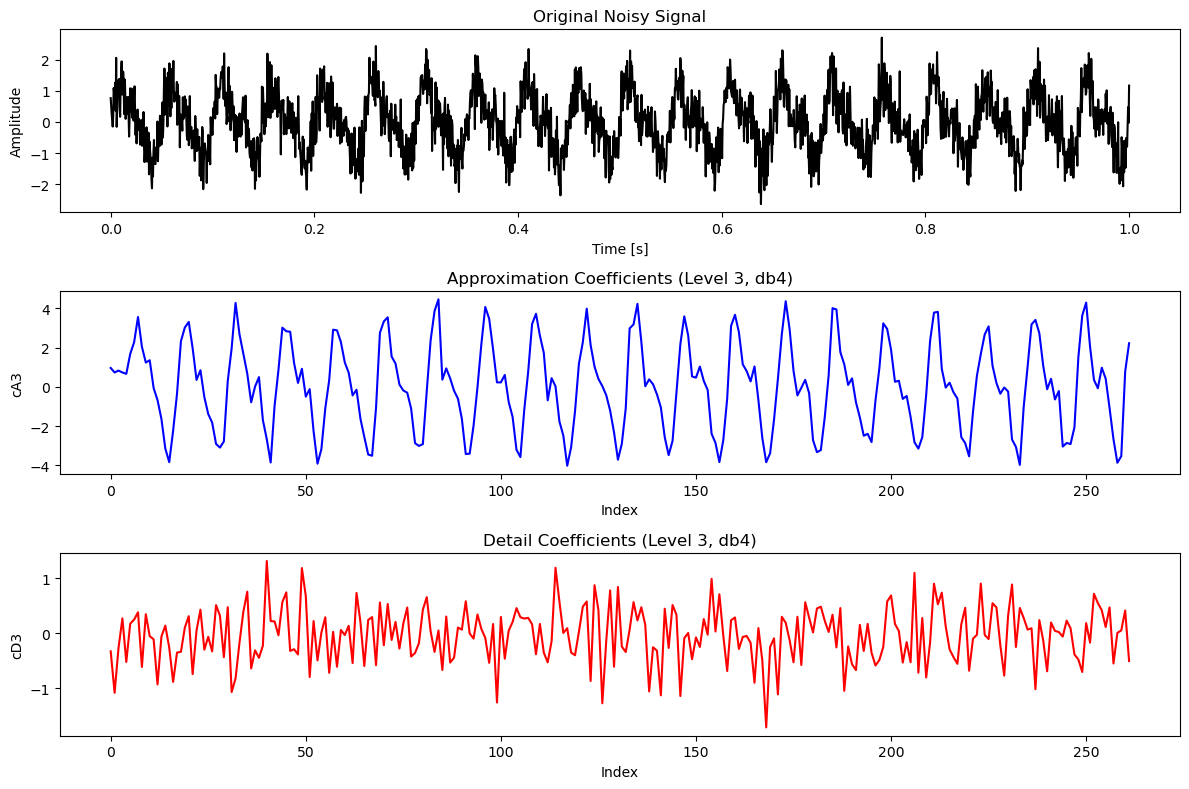

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pywt

# Simulated noisy signal
t = np.linspace(0, 1, num=2048)
signal = np.sin(40 * np.pi * t) + 0.5 * np.sin(80 * np.pi * t)
signal += 0.5 * np.random.randn(*t.shape)  # add noise

# Compute only approximation coefficients at level 3
cA3 = pywt.downcoef('a', signal, 'db4', level=3)

# Compute only detail coefficients at level 3
cD3 = pywt.downcoef('d', signal, 'db4', level=3)

# Plot
plt.figure(figsize=(12, 8))

# Original signal
plt.subplot(3, 1, 1)
plt.plot(t, signal, color='black')
plt.title("Original Noisy Signal")
plt.xlabel("Time [s]")
plt.ylabel("Amplitude")

# Approximation coefficients (level 3)
plt.subplot(3, 1, 2)
plt.plot(cA3, color='blue')
plt.title("Approximation Coefficients (Level 3, db4)")
plt.xlabel("Index")
plt.ylabel("cA3")

# Detail coefficients (level 3)
plt.subplot(3, 1, 3)
plt.plot(cD3, color='red')
plt.title("Detail Coefficients (Level 3, db4)")
plt.xlabel("Index")
plt.ylabel("cD3")

plt.tight_layout()
plt.savefig('./output/4.11_3l_wavelet_coefficients.png')
plt.show()

### 4.4.5 Multi-level Reconstruction
**2. Example 7: Reconstructing a Signal**


Reconstruction Mean Error: 1.77e-16
Reconstruction Max Error: 1.33e-15


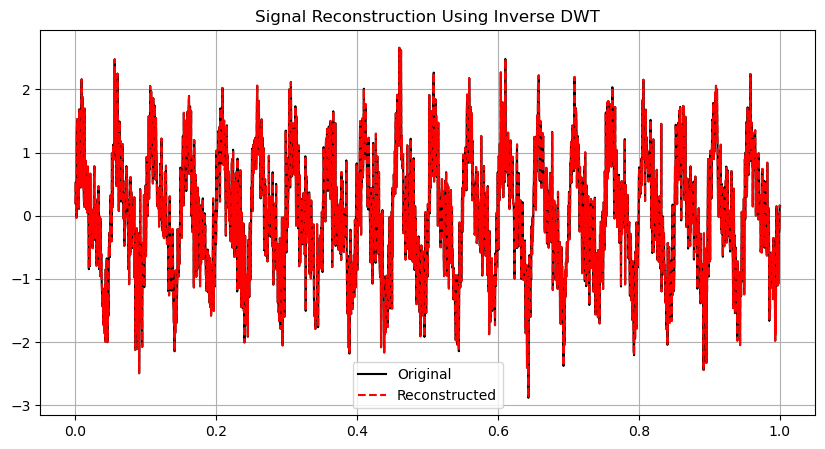

In [2]:
import pywt
import numpy as np
import matplotlib.pyplot as plt

# Simulated noisy signal
t = np.linspace(0, 1, num=2048)
signal = np.sin(40 * np.pi * t) + 0.5 * np.sin(80 * np.pi * t)
signal += 0.5 * np.random.randn(*t.shape)  # add noise

# Decompose using DWT
coeffs = pywt.wavedec(signal, 'db4', level=3)

# Reconstruct the signal from coefficients
signal_rec = pywt.waverec(coeffs, 'db4')

# Compute reconstruction errors
mean_error = np.mean(np.abs(signal - signal_rec))
max_error = np.max(np.abs(signal - signal_rec))

print(f"Reconstruction Mean Error: {mean_error:.2e}")
print(f"Reconstruction Max Error: {max_error:.2e}")

# Plot original vs reconstructed
plt.figure(figsize=(10, 5))
plt.plot(t, signal, label='Original', color='black')
plt.plot(t, signal_rec, '--', label='Reconstructed', color='red')
plt.title("Signal Reconstruction Using Inverse DWT")
plt.legend()
plt.grid(True)
plt.savefig('./output/4.12_3l_wavelet_reconstruction.png')
plt.show()

In [5]:
# Mean Absolute Error (MAE)
MAE = abs(sum(signal - signal_rec) / len(signal))

# Maximum Absolute Error (Max AE)
MAX_AE = max(abs(signal - signal_rec))

print('Mean Absolute Error:', MAE)
print('Maximum Absolute Error:', MAX_AE)

Mean Absolute Error: 5.826739644162332e-18
Maximum Absolute Error: 1.3322676295501878e-15


### 4.4.6 Multi-level Partial Reconstruction

**(c) Example 8: Multi-level Partial Reconstruction of Approximation and Details at 3 levels**

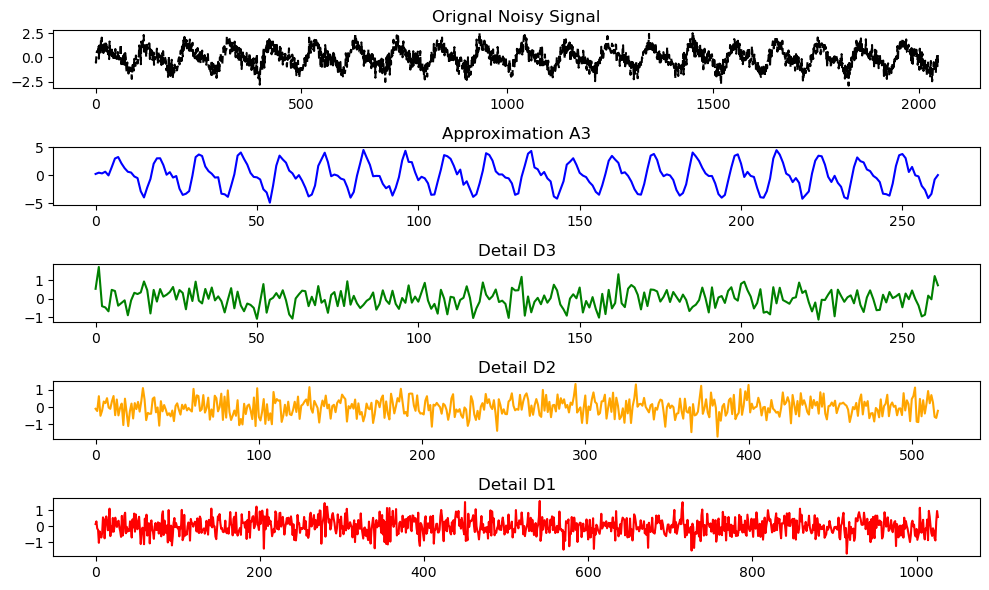

In [8]:
import numpy as np
import pandas as pd
import pywt
import matplotlib.pyplot as plt

# Load noisy signal
data = pd.read_csv("./data/noisy_sin.csv")
t = data["t"].values
signal = data["signal"].values

# 3-level wavelet decomposition
wavelet = "db4"
coeffs = pywt.wavedec(signal, wavelet, level=3)

# coeffs = [A3, D3, D2, D1]
A3, D3, D2, D1 = coeffs

# Plot subplots
fig, axes = plt.subplots(5, 1, figsize=(10, 6), sharex=False)

axes[0].plot(signal, '--', color="black")
axes[0].set_title("Orignal Noisy Signal")

axes[1].plot(A3, color="blue")
axes[1].set_title("Approximation A3")

axes[2].plot(D3, color="green")
axes[2].set_title("Detail D3")

axes[3].plot(D2, color="orange")
axes[3].set_title("Detail D2")

axes[4].plot(D1, color="red")
axes[4].set_title("Detail D1")

plt.tight_layout()
plt.savefig('./output/4.13_ml3_partial_rec.png')
plt.show()

**(d) Example: Multi-level Partial Reconstruction of Approximations at 4 levels**

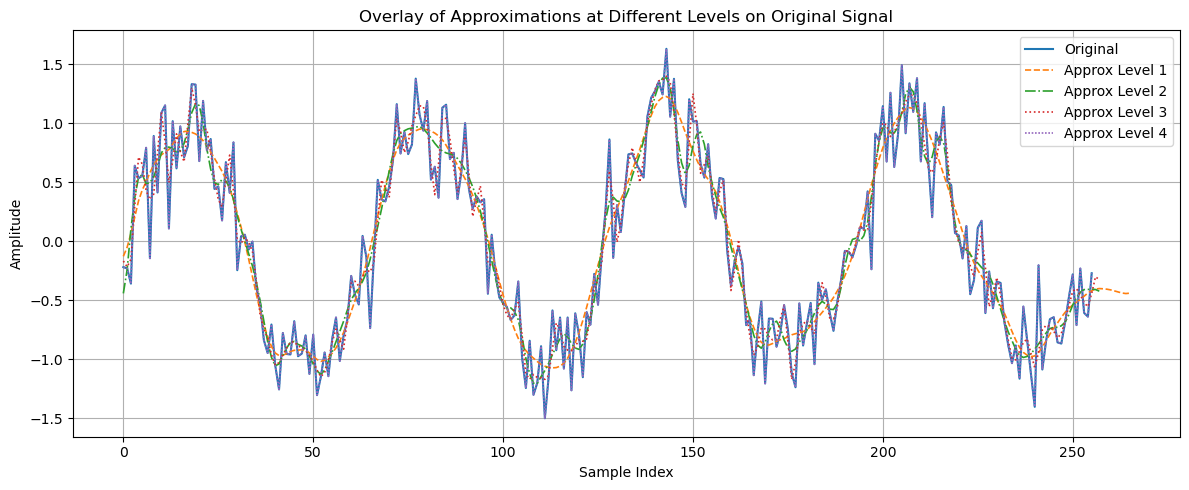

In [ ]:
import pywt
import numpy as np
import matplotlib.pyplot as plt

# Simulated signal
x = np.sin(np.linspace(0, 8 * np.pi, 256)) + 0.3 * np.random.randn(256)

# Decompose using DWT
wavelet = 'db6'
max_level = 4
coeffs = pywt.wavedec(x, wavelet, level=max_level)

# Reconstruct approximations at all levels
approx_levels = []
for level in range(1, max_level + 1):
    # Create coeffs with details up to level
    c = coeffs[:level + 1] + [None] * (max_level - level)
    approx = pywt.waverec(c, wavelet)
    approx_levels.append((level, approx))

# Plot
plt.figure(figsize=(12, 5))
plt.plot(x, label='Original', linewidth=1.5)

line_styles = ['--', '-.', ':', (0, (1, 1))]  # 4 distinct grayscale-friendly styles
for i, (level, approx) in enumerate(approx_levels):
    plt.plot(approx, linestyle=line_styles[i], label=f'Approx Level {level}', linewidth=1.2)

plt.title("Overlay of Approximations at Different Levels on Original Signal")
plt.xlabel("Sample Index")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("./output/4.14_ml_wavelet_approximations_overlay.png")
plt.show()

**3. Example: Compare the `pywt.upcoef()` and `pywt.upcoef()` for Multi-level Partial Reconstruction**

Numerical error metrics between upcoef() and waverec():
Approximation -> Mean error: 2.15e-01, Max error: 8.50e-01
Detail        -> Mean error: 1.22e-01, Max error: 7.04e-01


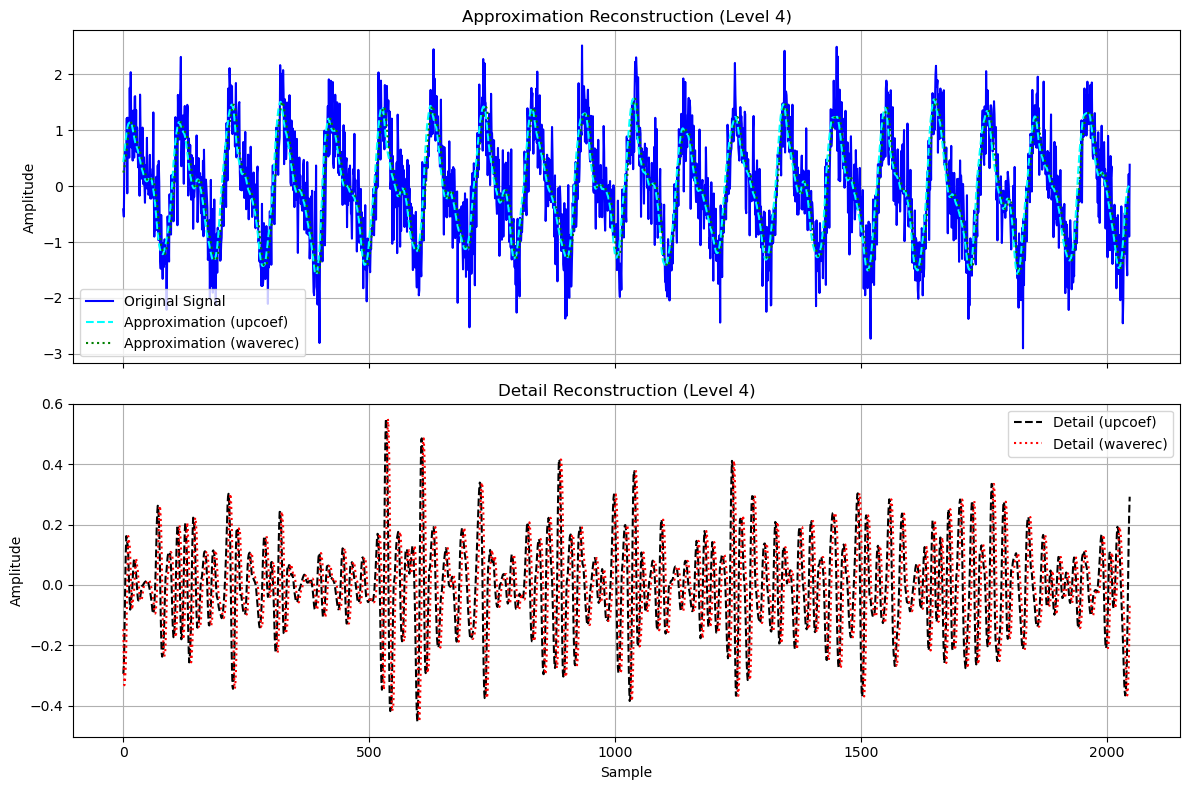

In [ ]:
import pywt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load the noisy signal
data = pd.read_csv("./data/noisy_sin.csv")
t = data["t"].values
signal = data["signal"].values

# Wavelet and decomposition level
wavelet = 'db5'
level = 4

# Multi-level DWT
coeffs = pywt.wavedec(signal, wavelet, level=level)
# coeffs = [cA4, cD4, cD3, cD2, cD1]
cA4, cD4, cD3, cD2, cD1 = coeffs

# ----------------------------
# Partial reconstruction using upcoef()
# ----------------------------
approx_up = pywt.upcoef('a', cA4, wavelet, level=level, take=len(signal))
detail_up = pywt.upcoef('d', cD4, wavelet, level=level, take=len(signal))

# ----------------------------
# Partial reconstruction using waverec()
# ----------------------------
# Approximation only: keep cA4, zero all details
cA_only = [cA4] + [np.zeros_like(c) for c in coeffs[1:]]
approx_rec = pywt.waverec(cA_only, wavelet)

# Detail at level 4 only: keep cD4, zero others
cD4_only = [np.zeros_like(cA4), cD4] + [np.zeros_like(c) for c in coeffs[2:]]
detail_rec = pywt.waverec(cD4_only, wavelet)

# ----------------------------
# Compute numerical error metrics
# ----------------------------
approx_error_mean = np.mean(np.abs(approx_up - approx_rec))
approx_error_max = np.max(np.abs(approx_up - approx_rec))

detail_error_mean = np.mean(np.abs(detail_up - detail_rec))
detail_error_max = np.max(np.abs(detail_up - detail_rec))

print("Numerical error metrics between upcoef() and waverec():")
print(f"Approximation -> Mean error: {approx_error_mean:.2e}, Max error: {approx_error_max:.2e}")
print(f"Detail        -> Mean error: {detail_error_mean:.2e}, Max error: {detail_error_max:.2e}")

# ----------------------------
# Plot results in subplots
# ----------------------------
fig, axs = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# Subplot 1: Original + approximations
axs[0].plot(signal, label='Original Signal', color='blue')
axs[0].plot(approx_up, '--', label='Approximation (upcoef)', color='cyan')
axs[0].plot(approx_rec, ':', label='Approximation (waverec)', color='green')
axs[0].set_title('Approximation Reconstruction (Level 4)')
axs[0].set_ylabel('Amplitude')
axs[0].legend()
axs[0].grid(True)

# Subplot 2: Details
axs[1].plot(detail_up, '--', label='Detail (upcoef)', color='black')
axs[1].plot(detail_rec, ':', label='Detail (waverec)', color='red')
axs[1].set_title('Detail Reconstruction (Level 4)')
axs[1].set_xlabel('Sample')
axs[1].set_ylabel('Amplitude')
axs[1].legend()
axs[1].grid(True)

plt.tight_layout()
plt.savefig('./output/4.15_ml_partial_reconstruction_subplots.png')
plt.show()


## 4.5 Choosing the Right Wavelet

### 4.5.3 Based on Visual Comparison


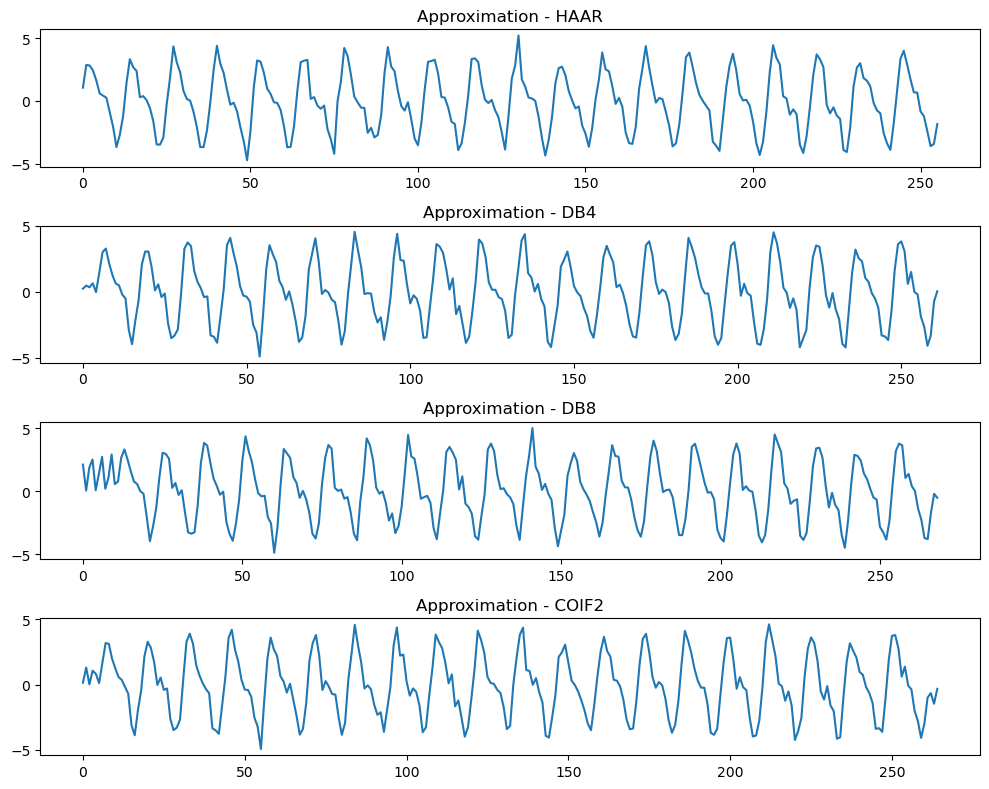

In [ ]:
import pywt
import pandas as pd
import matplotlib.pyplot as plt

# Load the noisy signal
data = pd.read_csv("./data/noisy_sin.csv")
t = data["t"].values
signal = data["signal"].values

# Define wavelets to compare
wavelets = ['haar', 'db4', 'db8', 'coif2']
fig, axes = plt.subplots(len(wavelets), 1, figsize=(10, 8))

# Perform wavelet decomposition and plot approximations
for i, wavelet in enumerate(wavelets):
    coeffs = pywt.wavedec(signal, wavelet, level=3)
    cA3 = coeffs[0]
    axes[i].plot(cA3)
    axes[i].set_title(f"Approximation - {wavelet.upper()}")

plt.tight_layout()
plt.savefig('./output/4.17_wavelet_decomposition_comparison.png')
plt.show()


### 4.5.4 Reconstruction Error Comparison Across Wavelets

haar    -> MAE: 2.8479e-16
db4     -> MAE: 1.8291e-16
db8     -> MAE: 2.1097e-16
coif2   -> MAE: 2.6515e-16
bior4.4 -> MAE: 7.6391e-13


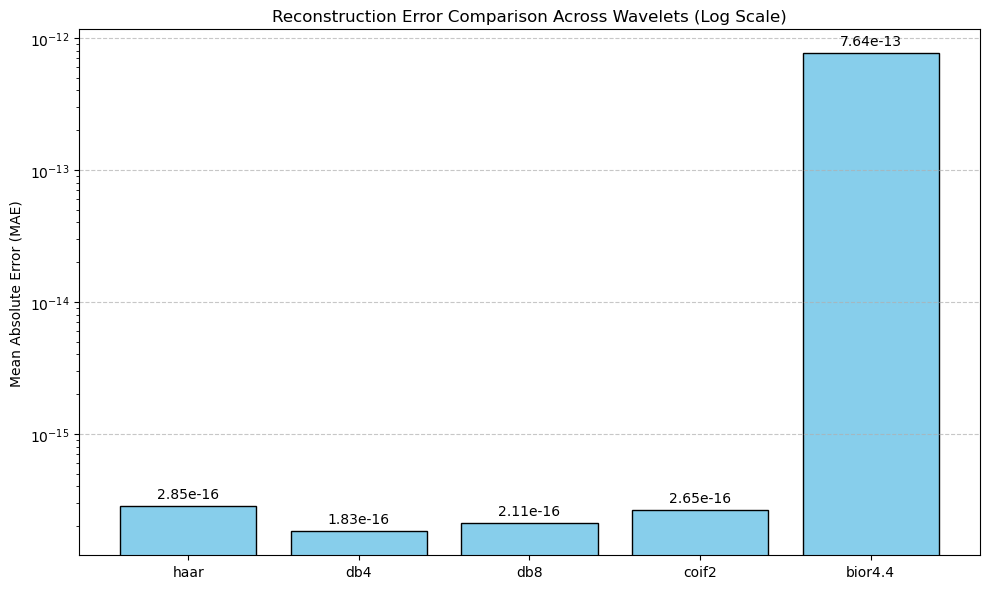

In [ ]:
import pywt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load the noisy signal
data = pd.read_csv("./data/noisy_sin.csv")
x = data["signal"].values

wavelets = ['haar', 'db4', 'db8', 'coif2', 'bior4.4']
errors = []

for wavelet in wavelets:
    coeffs = pywt.wavedec(x, wavelet, level=3)
    x_rec = pywt.waverec(coeffs, wavelet)
    
    mae = np.mean(np.abs(x - x_rec[:len(x)]))
    errors.append(mae)
    print(f"{wavelet:<7s} -> MAE: {mae:.4e}")

# Plot MAE comparison with log scale
plt.figure(figsize=(10, 6))
bars = plt.bar(wavelets, errors, color="skyblue", edgecolor="black")
plt.yscale('log')
plt.ylabel("Mean Absolute Error (MAE)")
plt.title("Reconstruction Error Comparison Across Wavelets (Log Scale)")
plt.grid(axis="y", linestyle="--", alpha=0.7)

# Add error labels on top of bars
for bar, err in zip(bars, errors):
    plt.text(bar.get_x() + bar.get_width()/2, err*1.1, f"{err:.2e}", 
             ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.savefig("./output/4.18_wavelet_reconstruction_error_comparison_log.png", dpi=300)
plt.show()


## 4.6 Signal Extension Modes

### 4.6.2 Extension Modes in PyWavelets

In [1]:
import pywt
# Check available modes
print("Available modes: \n", pywt.Modes.modes)

Available modes: 
 ['zero', 'constant', 'symmetric', 'periodic', 'smooth', 'periodization', 'reflect', 'antisymmetric', 'antireflect']


### 4.6.3 Inspect the Extended Signal

In [3]:
import pywt
import numpy as np

data = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9])
wavelet = pywt.Wavelet('db4')
pad_width = wavelet.dec_len - 1

# Apply symmetric padding manually
extended = pywt.pad(data, pad_widths=(pad_width,), mode='symmetric')
print("Extended Signal:", extended)

Extended Signal: [7 6 5 4 3 2 1 1 2 3 4 5 6 7 8 9 9 8 7 6 5 4 3]


### 4.6.5 Handling Border Effects

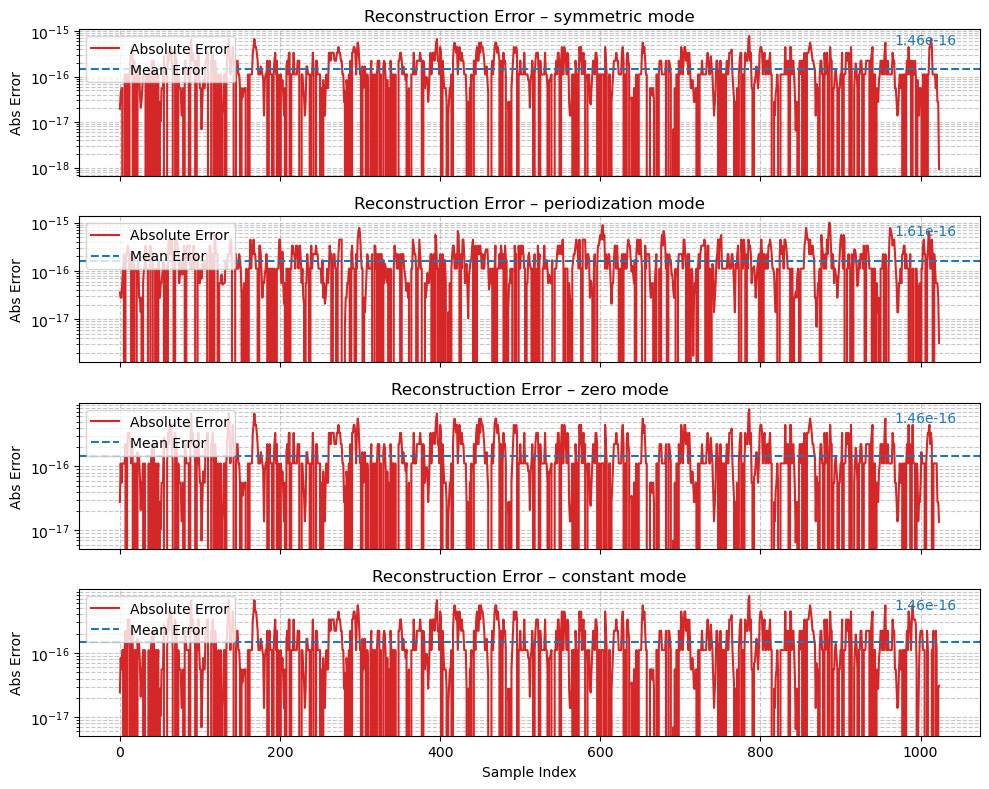

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pywt

# Generate signal (e.g., sine wave)
x = np.linspace(0, 1, 1024)
signal = np.sin(40 * np.pi * x)

# Different border handling modes
modes = ['symmetric', 'periodization', 'zero', 'constant']

# Plot setup
fig, axes = plt.subplots(len(modes), 1, figsize=(10, 8), sharex=True)

for i, mode in enumerate(modes):
    # Wavelet decomposition and reconstruction
    coeffs = pywt.wavedec(signal, 'db4', level=3, mode=mode)
    reconstructed = pywt.waverec(coeffs, 'db4', mode=mode)
    reconstructed = reconstructed[:len(signal)]

    # Reconstruction error
    error = np.abs(signal - reconstructed)

    # Mean error
    mean_error = np.mean(error)

    # Plot error
    axes[i].plot(error, color='tab:red', label='Absolute Error')

    # Plot mean error line
    axes[i].axhline(mean_error, color='tab:blue', linestyle='--', label='Mean Error')

    # Annotate mean error
    axes[i].text(len(signal)*1.02, mean_error*3, f"{mean_error:.2e}", 
                 ha='right', va='bottom', color='tab:blue', fontsize=10)

    # Subplot formatting
    axes[i].set_title(f"Reconstruction Error – {mode} mode")
    axes[i].set_ylabel("Abs Error")
    axes[i].set_yscale('log')
    axes[i].grid(True, which='both', linestyle='--', alpha=0.7)
    axes[i].legend(loc='upper left')

axes[-1].set_xlabel("Sample Index")
plt.tight_layout()
plt.savefig("./output/4.20_reconstruction_error_modes_log.png", dpi=300)
plt.show()


## 4.7 Maximum Decomposition Level

### 4.7.1 Manual Calculation

In [4]:
import numpy as np
import math
import pywt

# Simulated noisy signal
t = np.linspace(0, 1, num=2048)
s = np.sin(40 * np.pi * t) + 0.5 * np.sin(80 * np.pi * t)
s += 0.5 * np.random.randn(*t.shape)  # Add noise

# Define wavelet
wavelet = pywt.Wavelet('db4')
filter_len = wavelet.dec_len
data_len = len(s)

# Calculate maximum level manually
level = math.log(data_len / (filter_len - 1), 2)
max_level = math.floor(level)

print("Maximum decomposition level:", max_level)

Maximum decomposition level: 8


### 4.7.2 Using PyWavelets' Built-in Function

In [5]:
data_len = len(s)
w = pywt.Wavelet('db4')
max_l = pywt.dwt_max_level(data_len, w.dec_len)
print("Maximum decomposition level using PyWavelets:", max_l)

Maximum decomposition level using PyWavelets: 8


In [6]:
# Or more simply:

max_l = pywt.dwt_max_level(len(s), 'db4')
print("Maximum decomposition level using PyWavelets:", max_l)

Maximum decomposition level using PyWavelets: 8


## 4.8 Signal Length Considerations

### 4.8.1 Even-Length Signals

In [7]:
import numpy as np
import pywt

x = np.arange(16)  # even length
coeffs = pywt.wavedec(x, 'db1', level=2)
xr = pywt.waverec(coeffs, 'db1')
print(len(xr) == len(x))  # True

True


### 4.8.2 Odd-Length Signals

In [8]:
x = np.arange(15)  # odd length
coeffs = pywt.wavedec(x, 'db1', level=2)
xr = pywt.waverec(coeffs, 'db1')
print(len(xr) > len(x))  # Typically True, e.g., 16 > 15

True


### 4.8.3 Visual Illustration

In [9]:
import numpy as np
import pywt
import matplotlib.pyplot as plt

x_even = np.linspace(0, 1, 32)
x_odd = np.linspace(0, 1, 31)

for x in [x_even, x_odd]:
    coeffs = pywt.wavedec(x, 'db4', level=2)
    xr = pywt.waverec(coeffs, 'db4')
    print(f"Original length: {len(x)}, Reconstructed: {len(xr)}")

Original length: 32, Reconstructed: 32
Original length: 31, Reconstructed: 32


## 4.9 Energy Analysis and Parseval's Theorem

### 4.9.2 Visualize Energy Value and Distribution

Original signal energy: 511.50
Wavelet coefficients energy: 514.51
Energy preservation error: 3.005916


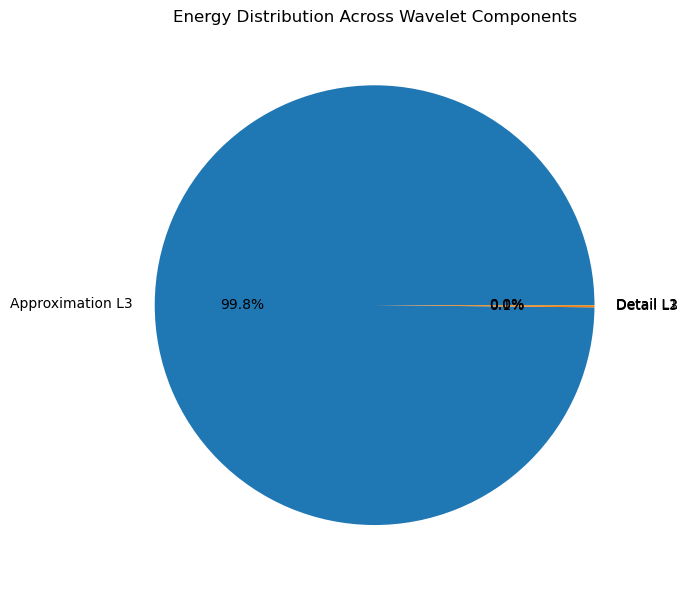

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pywt

# Generate example signal (e.g., a sine wave)
x = np.linspace(0, 1, 1024)
signal = np.sin(40 * np.pi * x)

# Perform 3-level wavelet decomposition
wavelet = 'db4'
coeffs = pywt.wavedec(signal, wavelet, level=3)
cA3, cD3, cD2, cD1 = coeffs  # Approximation and detail coefficients

# Compute energy
original_energy = np.sum(signal**2)

# Energy in wavelet coefficients
approx_energy = np.sum(cA3**2)
detail_energies = [np.sum(cD**2) for cD in [cD3, cD2, cD1]]
total_wavelet_energy = approx_energy + sum(detail_energies)

# Print energy values
print(f"Original signal energy: {original_energy:.2f}")
print(f"Wavelet coefficients energy: {total_wavelet_energy:.2f}")
print(f"Energy preservation error: {abs(original_energy - total_wavelet_energy):.6f}")

# Plot energy distribution
energy_distribution = [approx_energy] + detail_energies
labels = ['Approximation L3', 'Detail L3', 'Detail L2', 'Detail L1']

plt.figure(figsize=(10, 6))
plt.pie(energy_distribution, labels=labels, autopct='%1.1f%%')
plt.title("Energy Distribution Across Wavelet Components")
plt.tight_layout()
plt.savefig("./output/4.21.1_wavelet_energy_distribution.png", dpi=300)
plt.show()

**Try 'periodization' mode**:

Original signal energy: 511.50
Wavelet coefficients energy: 511.50
Energy preservation error: 0.000000


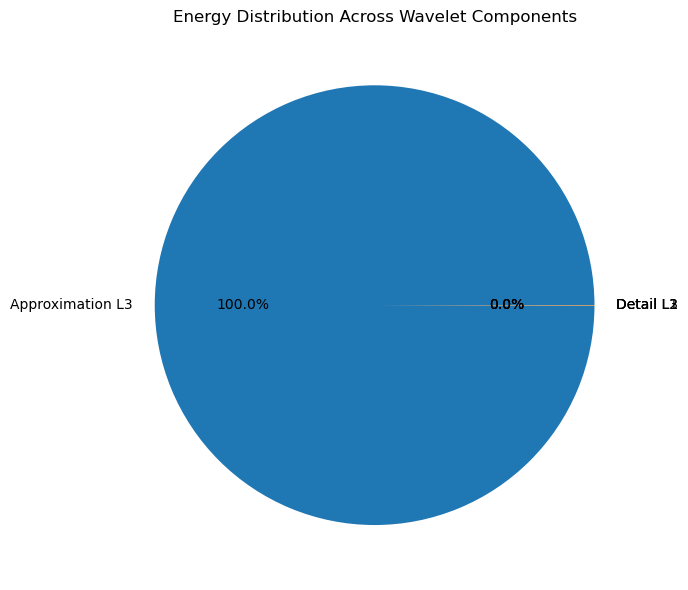

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pywt

# Generate example signal (e.g., a sine wave)
x = np.linspace(0, 1, 1024)
signal = np.sin(40 * np.pi * x)

# Perform 3-level wavelet decomposition
wavelet = 'db4'
coeffs = pywt.wavedec(signal, 'db4', level=3, mode='periodization')
# coeffs = pywt.wavedec(signal, wavelet, level=3)
cA3, cD3, cD2, cD1 = coeffs  # Approximation and detail coefficients

# Compute energy
original_energy = np.sum(signal**2)

# Energy in wavelet coefficients
approx_energy = np.sum(cA3**2)
detail_energies = [np.sum(cD**2) for cD in [cD3, cD2, cD1]]
total_wavelet_energy = approx_energy + sum(detail_energies)

# Print energy values
print(f"Original signal energy: {original_energy:.2f}")
print(f"Wavelet coefficients energy: {total_wavelet_energy:.2f}")
print(f"Energy preservation error: {abs(original_energy - total_wavelet_energy):.6f}")

# Plot energy distribution
energy_distribution = [approx_energy] + detail_energies
labels = ['Approximation L3', 'Detail L3', 'Detail L2', 'Detail L1']

plt.figure(figsize=(10, 6))
plt.pie(energy_distribution, labels=labels, autopct='%1.1f%%')
plt.title("Energy Distribution Across Wavelet Components")
plt.tight_layout()
plt.savefig("../images/4.21.2_wavelet_energy_distribution.png", dpi=300)  # Save the plot
plt.show()